# 09 — Scale and robustness

What learning costs, and what a learned reflex depends on · SOC4180
Robot and AI

Hong Jeong

<figure>
<a
href="https://colab.research.google.com/github/gnoejh/soc4180/blob/main/weeks/09-scale-and-robustness/lab.ipynb"><img
src="https://colab.research.google.com/assets/colab-badge.svg" /></a>
<figcaption>Open In Colab</figcaption>
</figure>

**Before you start, two things:**

1.  **Runtime → Change runtime type → CPU is enough.** No GPU is needed:
    nothing in this notebook trains or renders. The two policies were
    trained before (about 16 minutes each on a 36-core machine) and are
    downloaded.
2.  **File → Save a copy in Drive.** This notebook is opened from GitHub
    and is *not* saved. Without a copy, your work disappears when you
    close the tab.

The whole notebook runs in about a minute.

## One task this week

Week 8 ended every run the same way: *not enough steps*. This week has
two questions and **one task**.

1.  **The bill.** Why does learning need so many samples, and how does a
    simulator buy them — more processes, or a GPU?
2.  **The reflex.** Two push-recovery policies were trained with PPO,
    one in **one** world, one in **randomised** worlds. You test both,
    plus holding the crouch and week 8’s one-number ankle rule, in
    worlds **you** edit, with shoves of exact size.

The task, the code and the measured table are all one file:
**`weeks/09-scale-and-robustness/lab.py`**. You do not train anything.

**Layer 5**, learning — and the sim-to-real gap, measured without
leaving simulation.

------------------------------------------------------------------------

## Where this week sits on the map

Week 8 opened with a map of RL methods (value- or policy-based,
model-based or free, on- or off-policy, table or function). The course’s
route through it:

| week | method | what is learned | the step from the week before |
|---------|--------------------|------------------|--------------------------|
| 7 | value iteration | $V^*$, $\pi^*$ on a grid | exact, but needs $P$ and $R$ as tables |
| 7b | Q-learning, SARSA | a $Q$ table | drops $P$: learns from samples |
| 8 | policy gradient, parameter-space search | one ankle gain $\theta$ | drops the table: a policy with a parameter |
| **9 (this week)** | **PPO + domain randomisation** | **two networks (shipped)** | **scales $\theta$ to a network; trains in many worlds** |
| 10 | MPPI; behaviour cloning | a plan every step; a copy | uses the simulator as a model; learns from an expert, not a reward |
| 11 | perception and a check | — | the policy’s input becomes pixels and words |

Week 8 learned **one** number with a method you could read line by line.
PPO is the same idea (policy gradient, on-policy, model-free,
actor–critic) with **networks**: thousands of numbers, so millions of
samples. This week asks what that costs, and whether the result works in
worlds it never saw.

------------------------------------------------------------------------

## Colour code for the week

| symbol | meaning | colour |
|------------------------|------------------------|------------------------|
| ${\color{#3b7dd8}{N}}$ | the **budget**: environment steps (decisions) in one training run | <span style="color:#3b7dd8">blue</span> |
| ${\color{#e8743b}{n}}$ | environments stepping **together** (processes, GPU lanes) | <span style="color:#e8743b">orange</span> |
| ${\color{#2a9d5c}{r}}$ | the **rate** of one environment alone, steps per second | <span style="color:#2a9d5c">green</span> |
| ${\color{#c0392b}{s}}$ | the **serial** fraction: the part no extra environment shares | <span style="color:#c0392b">red</span> |
| ${\color{#8e44ad}{\xi}}$ | the **world**: friction, torso mass, servo stiffness | <span style="color:#8e44ad">purple</span> |
| ${\color{#3b7dd8}{\pi}}$ | the **policy**: 42 numbers in, 12 leg residuals out | <span style="color:#3b7dd8">blue</span> |

The first four belong to the bill, the last two to the reflex.

------------------------------------------------------------------------

## Setting up

In [1]:
import importlib.util, sys, urllib.request
from pathlib import Path
try:
    on_colab = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    on_colab = False
if on_colab:
    %pip install -q --upgrade "soc4180[rl] @ git+https://github.com/gnoejh/soc4180.git"
    BASE = "https://raw.githubusercontent.com/gnoejh/soc4180/main/weeks/09-scale-and-robustness/"
    Path("checkpoints").mkdir(exist_ok=True)
    for f in ("lab.py", "checkpoints/push_nominal.zip", "checkpoints/push_random.zip",
              "checkpoints/push_nominal.csv", "checkpoints/push_random.csv"):
        urllib.request.urlretrieve(BASE + f, f)
sys.path.insert(0, str(Path.cwd()))
import soc4180, lab

In [2]:
import inspect, time, warnings
from math import comb
import numpy as np
import matplotlib.pyplot as plt
from soc4180.envs import G1PushEnv, RANDOM_WORLD
warnings.filterwarnings("ignore")

def show(obj):
    """Print the source of a function from lab.py: the slide's code is the lab's code."""
    print(inspect.getsource(obj))

def show_part(obj, start, end):
    """Print part of a function from lab.py: from the first line containing
    `start` to the next line containing `end` (so the slide follows the lab)."""
    import textwrap
    lines = inspect.getsource(obj).splitlines()
    i = next((n for n, s in enumerate(lines) if start in s), None)
    j = next((n for n, s in enumerate(lines) if i is not None and n >= i and end in s), None)
    if i is None or j is None:
        raise ValueError(f"show_part: {start!r} .. {end!r} not found in {obj.__name__}")
    print(textwrap.dedent("\n".join(lines[i:j + 1])))

On Colab the first cell installs the package and downloads `lab.py` and
the two checkpoints; locally it does nothing but import. **Every code
slide below prints a piece of `lab.py`**, so the deck and the lab cannot
drift apart.

------------------------------------------------------------------------

## Why learning needs so many samples

PPO learns from **episodes it runs itself**. Each update nudges the
policy toward actions that were followed by high return, and the
estimate of “high” is an average over noisy episodes — it needs many of
them.

| run | budget ${\color{#3b7dd8}{N}}$ (decisions) | what it learned |
|------------------------|------------------------|------------------------|
| week 8, `G1WalkEnv` | 30 k | not to fall — not to walk |
| **this week’s checkpoints** | **3 M** | a push-recovery reflex |
| a tuned humanoid run (MuJoCo Playground, read from the library) | Berkeley Humanoid **150 M** at 8192 environments; Op3 100 M | to walk on command |

**Two kinds of step.** ${\color{#3b7dd8}{N}}$ counts *decisions*. The G1
environments decide every 20 ms and simulate every 2 ms, so one decision
is **10 physics steps**: a 150 M budget is 1.5 billion physics steps.

------------------------------------------------------------------------

## The learning curve of the checkpoints

nominal : 3 M decisions in 967 s (16 min); episode length 116 -> 164 of 250
random  : 3 M decisions in 975 s (16 min); episode length 98 -> 169 of 250

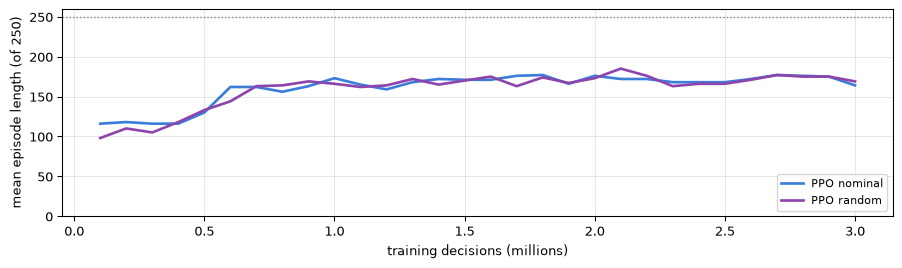

In [3]:
fig, ax = plt.subplots(figsize=(9.5, 2.9))
for name, c in (("nominal", "#3b7dd8"), ("random", "#8e44ad")):
    d = np.loadtxt(f"checkpoints/push_{name}.csv", delimiter=",", skiprows=1)  # steps, seconds, length, return
    ax.plot(d[:, 0] / 1e6, d[:, 2], color=c, lw=2, label=f"PPO {name}")
    print(f"{name:8s}: {d[-1, 0] / 1e6:.0f} M decisions in {d[-1, 1]:.0f} s ({d[-1, 1] / 60:.0f} min); "
          f"episode length {d[0, 2]:.0f} -> {d[-1, 2]:.0f} of 250")
ax.axhline(250, color="0.5", ls=":", lw=1)
ax.set_xlabel("training decisions (millions)"); ax.set_ylabel("mean episode length (of 250)")
ax.set_ylim(0, 260); ax.grid(alpha=0.3); ax.legend(fontsize=8, loc="lower right")
fig.tight_layout(); plt.show()

**Episode length is the score**: an episode ends early only by falling.
The curve flattens below 250 because training shoves go up to 200 N —
some shoves no stance of this robot survives. Flat is the task’s ceiling
here.

------------------------------------------------------------------------

## The arithmetic of a run

One environment makes ${\color{#2a9d5c}{r}}$ decisions per second;
${\color{#e8743b}{n}}$ environments that **really run at once** make
${\color{#e8743b}{n}}{\color{#2a9d5c}{r}}$. The learner’s update is a
part ${\color{#c0392b}{s}}$ that no extra environment shares:

$$T({\color{#e8743b}{n}}) = \frac{{\color{#3b7dd8}{N}}}{{\color{#2a9d5c}{r}}}\Big({\color{#c0392b}{s}} + \frac{1-{\color{#c0392b}{s}}}{{\color{#e8743b}{n}}}\Big)
\qquad\Rightarrow\qquad
\text{speed-up } S({\color{#e8743b}{n}}) = \frac{1}{{\color{#c0392b}{s}} + (1-{\color{#c0392b}{s}})/{\color{#e8743b}{n}}} \;\le\; \frac{1}{{\color{#c0392b}{s}}}$$

This is **Amdahl’s law**: with ${\color{#c0392b}{s}} = 0.01$ no number
of environments buys more than 100×. Your laptop’s
${\color{#2a9d5c}{r}}$:

In [4]:
env = G1PushEnv(); env.push_max = 0.0
obs, _ = env.reset(seed=0); hold = np.zeros(12, np.float32)
t0 = time.perf_counter(); m = 500
for _ in range(m):
    obs, _, fell, done, _ = env.step(hold)
    if fell or done:
        obs, _ = env.reset()
r = m / (time.perf_counter() - t0)
print(f"r = {r:,.0f} decisions/s on one core here ({env.decimation} physics steps each)")
print(f"N = 3 M   -> {3e6 / r / 3600:5.1f} h on one core")
print(f"N = 150 M -> {150e6 / r / 3600:5.1f} h on one core")

r = 1,259 decisions/s on one core here (10 physics steps each)
N = 3 M   ->   0.7 h on one core
N = 150 M ->  33.1 h on one core

------------------------------------------------------------------------

## Buying samples on a CPU: processes

Measured on the 36-core machine these slides were written on (quiet
machine):

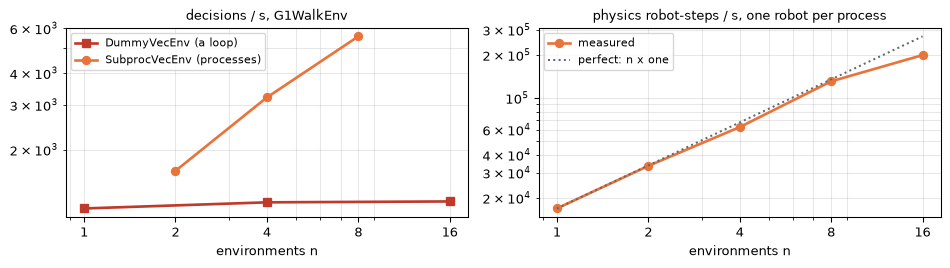

In [5]:
# Quoted, not run here (timings need a quiet machine): G1WalkEnv decisions/s with
# Stable-Baselines3's two vector environments, and physics-only robot-steps/s
# with one robot per process.
dummy = {1: 1173, 4: 1240, 16: 1250}                  # DummyVecEnv: n envs, ONE process
subproc = {2: 1649, 4: 3205, 8: 5570}                 # SubprocVecEnv: one process each
procs = {1: 16822, 2: 33382, 4: 62410, 8: 130429, 16: 199062}
fig, (a0, a1) = plt.subplots(1, 2, figsize=(10, 2.9))
a0.loglog(list(dummy), list(dummy.values()), "s-", color="#c0392b", lw=2, label="DummyVecEnv (a loop)")
a0.loglog(list(subproc), list(subproc.values()), "o-", color="#e8743b", lw=2, label="SubprocVecEnv (processes)")
a0.set_title("decisions / s, G1WalkEnv", fontsize=10)
ks = np.array(list(procs)); a1.loglog(ks, list(procs.values()), "o-", color="#e8743b", lw=2, label="measured")
a1.loglog(ks, procs[1] * ks, ":", color="0.4", label="perfect: n x one")
a1.set_title("physics robot-steps / s, one robot per process", fontsize=10)
for ax in (a0, a1):
    ax.set_xlabel("environments n"); ax.grid(alpha=0.3, which="both"); ax.legend(fontsize=8)
    ax.set_xticks([1, 2, 4, 8, 16]); ax.set_xticklabels([1, 2, 4, 8, 16])
fig.tight_layout(); plt.show()

- **“Vectorised” is not “parallel”.** `DummyVecEnv` steps its
  environments in a loop on one core: 16 of them give the throughput of
  one.
- **`SubprocVecEnv` scales — until the cores run out.** The checkpoints
  used 16 processes; a Colab CPU runtime has 2. One process at ~1300
  decisions/s puts 150 M decisions at **more than a day** (printed for
  this machine on the previous slide).

------------------------------------------------------------------------

## Buying samples on a GPU: the idea

A GPU does not run Python processes; it runs the **same instructions on
thousands of numbers at once**. **MJX** is MuJoCo rewritten in JAX so
the physics of thousands of robots becomes one array computation:

``` python
import jax
from mujoco import mjx

def step(state, action):              # written for ONE robot
    ...                               # set ctrl, mjx.step ten times, build obs and reward
    return state, obs, reward

step_all = jax.jit(jax.vmap(step))    # vmap: a batch of n robots; jit: compile once with XLA
states, obs, rewards = step_all(states, actions)   # 8192 robots, one call
```

- **`vmap`** moves the loop over robots *inside* the compiled code;
  **`jit`** traces the function once and compiles it. The first call is
  slow (compiling), later calls are fast.
- The price of “trace once”: **no Python `if` on array values, fixed
  shapes, no early exit** — every robot runs the same instructions.
- This is how the 150 M runs are done. **Nothing in this course needs
  it**: every lab runs on a laptop CPU, and the GPU route is optional.

------------------------------------------------------------------------

## The reflex: take a shove

`G1PushEnv` is week 7’s `G1WalkEnv` standing still (target speed 0),
with a **shove** once per 5-second episode: 0.2 s on the torso, at a
random moment between 1 and 3 s. Same 42 observations (IMU gravity and
gyro, leg angles and speeds, last action) and 12 leg residuals at 50 Hz.
Reward per decision:

$$r_t = \underbrace{1.5\,e^{-v_x^2/0.25}}_{\text{stay put}}
+ \underbrace{0.5\,(-g_z)}_{\text{upright}}
- \underbrace{0.01\,\lVert a_t\rVert^2}_{\text{effort}}
- \underbrace{0.05\,\lVert a_t - a_{t-1}\rVert^2}_{\text{smooth}}
+ \underbrace{0.5}_{\text{alive}}$$

An episode ends after 250 decisions, or by a **fall**: pelvis below 0.5
m or the torso tilted past 44°. The policy **does not see the shove
coming** and **does not see the world it is in**.

In [6]:
from stable_baselines3 import PPO
agent = PPO.load("checkpoints/push_random.zip", device="cpu")
print(f"read from the checkpoint: {agent.n_envs} processes, n_steps {agent.n_steps}, batch {agent.batch_size}, "
      f"epochs {agent.n_epochs}, gamma {agent.gamma}, net {agent.policy_kwargs.get('net_arch')}, "
      f"log_std_init {agent.policy_kwargs.get('log_std_init')}")

read from the checkpoint: 16 processes, n_steps 256, batch 1024, epochs 5, gamma 0.99, net [128, 128], log_std_init -2.0

------------------------------------------------------------------------

## What “robust” means

A policy is trained on a **distribution of worlds**
${\color{#8e44ad}{\xi}}$. “Nominal” is one point; “random” is a box,
drawn afresh every episode:

In [7]:
for k, (lo, hi) in RANDOM_WORLD.items():
    print(f"  {k:9s} nominal {('1.0' if k != 'mass' else '0.0'):>4s}    randomised: uniform {lo:+5.1f} .. {hi:+5.1f}")

  friction  nominal  1.0    randomised: uniform  +0.3 ..  +1.2
  mass      nominal  0.0    randomised: uniform  -5.0 .. +10.0
  kp        nominal  1.0    randomised: uniform  +0.7 ..  +1.3

`friction` scales every surface’s friction, `mass` adds kilograms to the
torso, `kp` scales every servo’s stiffness (damping follows, same
damping ratio).

> **“Robust” always means “robust to something”**: to the worlds it
> trained on, plus a margin that has to be measured, not assumed.

Mass, friction and motor strength are exactly the numbers a real robot
gets wrong. A world outside the training distribution is the
**sim-to-real gap**, and we can make one in simulation.

------------------------------------------------------------------------

## Domain randomisation, written out

**One world.** In a fixed world ${\color{#8e44ad}{\xi}}$ an episode
$\tau$ is random (the shove, the start); PPO maximises
$J({\color{#3b7dd8}{\pi}};{\color{#8e44ad}{\xi}}) = \mathbb E_{\tau}[R(\tau)]$.
A policy trained there may rely on *anything* true there — this exact
torso mass, this exact knee stiffness — for free.

**We do not know the world.** Write our belief as a distribution
$p({\color{#8e44ad}{\xi}})$ (here uniform on the box above) and average:

$$J_{\text{DR}}({\color{#3b7dd8}{\pi}}) = \mathbb E_{{\color{#8e44ad}{\xi}} \sim p}\big[J({\color{#3b7dd8}{\pi}};{\color{#8e44ad}{\xi}})\big]
= \int p({\color{#8e44ad}{\xi}})\, J({\color{#3b7dd8}{\pi}};{\color{#8e44ad}{\xi}})\, d{\color{#8e44ad}{\xi}}$$

**PPO already computes this.** `reset` draws a fresh
${\color{#8e44ad}{\xi}}$ each episode, so the batch average is a
Monte-Carlo estimate of $\mathbb E_{\xi}\mathbb E_{\tau}$. No change to
PPO: one line in `reset` changes the objective, and the policy must
become a feedback controller for a **family** of robots.

What it cannot promise: a world outside the box has weight **zero** in
$J_{\text{DR}}$. Whatever happens there is luck until it is measured.

------------------------------------------------------------------------

## The code (1): the policies under test

In [8]:
show(lab.make_policies)

def make_policies():
    from stable_baselines3 import PPO

    nominal = PPO.load(HERE / "checkpoints" / "push_nominal.zip", device="cpu")
    randomised = PPO.load(HERE / "checkpoints" / "push_random.zip", device="cpu")

    def hold(obs):
        return np.zeros(12, np.float32)

    def ankle(obs):                                   # week 8: one learned number
        a = np.zeros(12, np.float32)
        a[4] = a[10] = np.clip(2.0 * obs[0], -1, 1)
        return a

    return {
        "hold": hold,
        "ankle (wk 8)": ankle,
        "PPO nominal": lambda obs: nominal.predict(obs, deterministic=True)[0],
        "PPO random": lambda obs: randomised.predict(obs, deterministic=True)[0],
    }


Four controllers, one signature: 42 observations in, 12 residuals out.
`hold` does nothing; `ankle` is week 8’s one learned number (it turns
both ankle **pitches** against the forward tilt $g_x$ — note that this
week’s shoves are sideways); the two PPO networks act
**deterministically** (the mean action), because that is what you would
deploy.

------------------------------------------------------------------------

## `make_policies`, line by line (1): what an action is

An action is **12 numbers in $[-1, 1]$**, one per leg servo.
`G1PushEnv.step` clips it and turns it into joint targets:
`target[self.leg_qpos] += self.action_scale * action`, with
`action_scale = 0.3`. So slot $i$ asks for **crouch angle
$+\,0.3 \times a_i$ rad**; $a = 0$ means “hold the crouch”. Waist and
arms are always held at the crouch.

In [9]:
probe = G1PushEnv()
names = [probe.model.joint(int(j)).name.replace("_joint", "")
         for q in probe.leg_qpos for j in np.where(probe.model.jnt_qposadr == q)[0]]
for i, n in enumerate(names):
    print(f"a[{i:2d}] {n:18s}", end="\n" if i % 3 == 2 else "  ")

a[ 0] left_hip_pitch      a[ 1] left_hip_roll       a[ 2] left_hip_yaw      
a[ 3] left_knee           a[ 4] left_ankle_pitch    a[ 5] left_ankle_roll   
a[ 6] right_hip_pitch     a[ 7] right_hip_roll      a[ 8] right_hip_yaw     
a[ 9] right_knee          a[10] right_ankle_pitch   a[11] right_ankle_roll  

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `def hold(obs): return np.zeros(12, ...)` | every residual 0: the servos hold the crouch | the baseline: no controller beyond the servos |
| `a[4] = a[10] = np.clip(2.0 * obs[0], -1, 1)` | both **ankle pitches** (slots 4 and 10) get $2\,g_x$, the forward tilt; everything else 0 | week 8’s one learned number, as a ${\color{#3b7dd8}{\pi}}$ with the same signature |

------------------------------------------------------------------------

## `make_policies`, line by line (2): the PPO networks

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `from stable_baselines3 import PPO` | imported inside the function | the lab prints `uv sync --extra rl` if it is missing |
| `PPO.load(HERE / "checkpoints" / "push_nominal.zip", device="cpu")` | rebuilds the trained network from the zip: weights plus the settings it was trained with | nothing is trained this week; a small network runs fine on a CPU |
| `nominal.predict(obs, deterministic=True)` | returns `(action, state)`; `[0]` keeps the 12 numbers | `state` is for recurrent networks, unused here |
| `deterministic=True` | gives the **mean** of the policy’s Gaussian, no sampled noise | the noise is for *exploring* in training; a test measures the controller you would deploy, and repeats exactly |
| the returned dict | four names → four functions `obs -> 12 numbers` | `main` loops over them without knowing which is which |

------------------------------------------------------------------------

## `make_policies`, line by line (3): what `obs` holds

All four ${\color{#3b7dd8}{\pi}}$ read the same 42 numbers, built by
`G1WalkEnv._observation` (`G1PushEnv` inherits it):

| slots | contents | from |
|------------------------|------------------------|------------------------|
| 0–2 | unit gravity in the pelvis frame: `obs[0]` is $g_x$, the forward tilt `ankle` uses | the pelvis’s true orientation, `qpos[3:7]` (`gravity_body`; a real robot would estimate it from an IMU, week 6) |
| 3–5 | angular velocity | the torso IMU’s gyro |
| 6–17 | 12 leg angles **minus the crouch** (0 = in the crouch) | `qpos[leg_qpos] - nominal[leg_qpos]` |
| 18–29 | 12 leg joint speeds | `qvel[leg_dof]` |
| 30–41 | the previous action | `_prev_action` |

**Not in `obs`**: the shove, the ${\color{#8e44ad}{\xi}}$ it is in, the
pelvis’s speed and height. A policy can only react to a shove through
what it does to the tilt, the gyro and the joints.

------------------------------------------------------------------------

## The code (2): the worlds you change

In [10]:
print("WORLDS = {")
for name, w in lab.WORLDS.items():
    print(f"    {name!r:24s}: {w},")
print("}")
print(f"PUSHES = {lab.PUSHES}        # newtons, sideways, 0.2 s")

WORLDS = {
    'nominal'               : {'friction': 1.0, 'mass': 0.0, 'kp': 1.0},
    'heavy (+15 kg)'        : {'friction': 1.0, 'mass': 15.0, 'kp': 1.0},
    'ice (friction 0.2)'    : {'friction': 0.2, 'mass': 0.0, 'kp': 1.0},
    'weak servos (kp 0.6)'  : {'friction': 1.0, 'mass': 0.0, 'kp': 0.6},
}
PUSHES = (0, 60, 80, 100, 120)        # newtons, sideways, 0.2 s

Each entry is **one** world, used for every episode of its row. Compare
with the training box: ice (friction 0.2 \< 0.3), heavy (+15 kg \> +10)
and weak servos (kp 0.6 \< 0.7) are **all just outside** what PPO random
trained on. The nominal world is inside both training sets.

------------------------------------------------------------------------

## How a world reaches the model

`lab.py` only names the numbers; `G1PushEnv` writes them into the MuJoCo
model. `reset` draws each knob from its range (`rng.uniform(*v)`, so a
range `(v, v)` gives exactly `v`) and calls `set_world`:

In [11]:
from soc4180.envs import G1PushEnv as _P
print(inspect.getsource(_P.set_world))

    def set_world(self, **values):
        """Apply one world: friction scale, added torso mass (kg), servo stiffness scale."""
        self.drawn.update(values)
        self.model.geom_friction[:, 0] = self._friction0 * self.drawn["friction"]
        self.model.body_mass[self.torso] = self._mass0 + self.drawn["mass"]
        k = self.drawn["kp"]
        self.model.actuator_gainprm[:, 0] = self._gain0 * k
        self.model.actuator_biasprm[:, 1] = self._bias0[:, 0] * k
        self.model.actuator_biasprm[:, 2] = self._bias0[:, 1] * np.sqrt(k)   # keep the damping ratio


The `_0` arrays are the model’s own values, copied once in `__init__`,
so each world is set **from the original robot**, never on top of the
last world. Nothing here changes the observation: the
${\color{#3b7dd8}{\pi}}$ is not told which ${\color{#8e44ad}{\xi}}$ it
is in.

------------------------------------------------------------------------

## What each knob does physically

In [12]:
m = probe.model
print(f"torso_link {m.body_mass[probe.torso]:.2f} kg of {m.body_mass.sum():.1f} kg; "
      f"leg servo kp {m.actuator_gainprm[0, 0]:.0f}; friction values in the model {sorted(set(m.geom_friction[:, 0]))}")

torso_link 7.82 kg of 33.3 kg; leg servo kp 500; friction values in the model [np.float64(0.6), np.float64(1.0)]

| knob | the line in `set_world` | what changes in the robot |
|------------------------|------------------------|------------------------|
| `friction` | `geom_friction[:, 0] = _friction0 * f` | sliding friction $\mu$ of **every** geom (floor and feet) × $f$. A foot slips once the sideways force on it exceeds $\mu$ × its normal force |
| `mass` | `body_mass[torso] = _mass0 + m` | kilograms on the torso, high above the ankles (inertia unchanged): more torque needed to hold the same crouch |

*(continued on the next slide)*

------------------------------------------------------------------------

## What each knob does physically (cont.)

| knob | the line in `set_world` | what changes in the robot |
|------------------------|------------------------|------------------------|
| `kp` | `gainprm[:, 0] = _gain0 * k`; `biasprm[:, 1]` × `k` | stiffness of all 29 servos: torque $= k_p(\text{target}-q) - k_v\dot q$. Weaker per radian, so more sag under the same load ($1/k_p$, week 5) |
| damping | `biasprm[:, 2]` × `np.sqrt(k)` | $k_v \propto \sqrt{k}$ keeps $\zeta = k_v/2\sqrt{k_p M}$ (week 5): only the stiffness changes |

------------------------------------------------------------------------

## The code (3): one count

In [13]:
show(lab.survived)

def survived(env, policy, world, push, episodes, *, sideways=True, record=False):
    env.world = {k: (v, v) for k, v in world.items()}      # this world, every episode
    ok, frames = 0, []
    for k in range(episodes):
        env.push_max = max(push, 1.0)
        obs, _ = env.reset(seed=k)                         # the moment of the push differs by seed
        if sideways:
            env.push_force = np.array([0.0, float(push)])
        else:                                              # random direction, exactly `push` N
            env.push_force *= push / max(np.linalg.norm(env.push_force), 1e-9)
        while True:
            obs, _, fell, done, _ = env.step(policy(obs))
            if record:
                frames.append(env.data.qpos.copy())
            if fell or done:
                break
        ok += int(not fell)
    return ok, frames


- `env.world = {k: (v, v)}`: a range of width zero — **this** world,
  every episode.
- `reset(seed=k)`: episode $k$ has the same crouch and push moment **for
  every policy**, so rows are compared on identical trials (a paired
  test).
- `push_force = [0, push]`: a shove of **exactly** `push` newtons,
  sideways.

------------------------------------------------------------------------

## `survived`, line by line (1): setting up one episode

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `env.world = {k: (v, v) for k, v in world.items()}` | every knob gets a range of width zero | `reset` draws `uniform(v, v) = v`: **this** ${\color{#8e44ad}{\xi}}$, every episode |
| `ok, frames = 0, []` | the count, and the poses for a replay |  |
| `for k in range(episodes):` | `episodes` trials (`main` passes `--episodes`, 10 by default) | the count is $k$ of $n$ (binomial: *Measuring robustness honestly*) |
| `env.push_max = max(push, 1.0)` | `reset` draws a random shove up to `push_max` | at `push_max = 0` reset **skips** that draw and every later draw shifts; $\ge 1$ keeps the same draws for every column |

*(continued on the next slide)*

------------------------------------------------------------------------

## `survived`, line by line (1): setting up one episode (cont.)

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `obs, _ = env.reset(seed=k)` | from seed `k`: the world draws, a direction, a size, the **moment** (uniform 1–3 s), the crouch ±0.02 rad | the same seed gives the same moment and crouch to every policy and push: a paired test |
| `env.push_force = np.array([0.0, float(push)])` | overwrites the random shove: $x$ 0, $y$ = `push` N | **sideways** and **exact**; $+y$ is the robot’s left |
| `env.push_force *= push / max(np.linalg.norm(...), 1e-9)` | `--any-direction`: keeps the random direction, rescales to exactly `push` N | the `1e-9` avoids dividing by zero |

------------------------------------------------------------------------

## `survived`, line by line (2): running it and counting

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `env.step(policy(obs))` | one decision: 12 residuals → servo targets → **10 physics steps** (20 ms) | the policy runs at 50 Hz |
| `obs, _, fell, done, _ = ...` | gymnasium’s `terminated` is named `fell`, `truncated` is `done` | `fell`: pelvis below 0.5 m or tilt past 44°; `done`: 250 decisions (5 s) |
| `if record: frames.append(env.data.qpos.copy())` | keeps every pose | only `main`’s replay asks for it |

*(continued on the next slide)*

------------------------------------------------------------------------

## `survived`, line by line (2): running it and counting (cont.)

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `if fell or done: break` | the episode ends either way |  |
| `ok += int(not fell)` | survived = ended by the clock, not by a fall |  |
| `return ok, frames` | an integer `0 .. episodes`, and the poses | one cell of the table is `ok` |

**Where the shove happens**: `G1PushEnv.step`, before each decision:

In [14]:
print(inspect.getsource(_P.step))

    def step(self, action):
        # The push is on for whole decisions: at 50 Hz, 0.2 s is ten of them.
        t = self.data.time
        on = self.push_time <= t < self.push_time + self.push_seconds
        self.data.xfrc_applied[self.torso, :2] = self.push_force if on else 0.0
        return super().step(action)


A force on **`torso_link`** (`xfrc_applied`, world frame, $x$ and $y$
only) for whole decisions while `push_time <= t < push_time + 0.2`: ten
of them.

------------------------------------------------------------------------

## The code (4): the table, `main`

In [15]:
show_part(lab.main, "env = G1PushEnv()", 'print(f"({time.time()')

env = G1PushEnv()
print(f"episodes survived out of {args.episodes}; a shove of exactly N newtons, "
      f"{'any direction' if args.any_direction else 'sideways'}, 0.2 s\n")
print(f"{'world':22s} {'policy':14s} " + " ".join(f"{p:>5} N" for p in PUSHES))
t0 = time.time()
for wname, world in WORLDS.items():
    for pname, policy in policies.items():
        counts = [survived(env, policy, world, p, args.episodes, sideways=not args.any_direction)[0]
                  for p in PUSHES]
        print(f"{wname:22s} {pname:14s} " + " ".join(f"{c:7d}" for c in counts), flush=True)
    print()
print(f"({time.time() - t0:.0f} s)")

`main` first reads the flags and calls `make_policies` (inside a `try`:
without `--extra rl` it prints what to install and stops). Then the part
above prints the table, and last it replays one episode in the viewer.

------------------------------------------------------------------------

## `main`, line by line: one table

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `env = G1PushEnv()` | **one** environment for the whole table | `survived` re-sets its world each call |
| `for wname, world in WORLDS.items():` | the rows’ blocks: 4 ${\color{#8e44ad}{\xi}}$ as shipped | your edits to `WORLDS` appear here |
| `for pname, policy in policies.items():` | 4 ${\color{#3b7dd8}{\pi}}$ per world: one printed row each |  |
| `[survived(env, policy, world, p, args.episodes, ...)[0] for p in PUSHES]` | one count per push size: 5 columns | `[0]` keeps `ok`, drops the frames |

*(continued on the next slide)*

------------------------------------------------------------------------

## `main`, line by line: one table (cont.)

| code | what it does | why |
|------------------------|------------------------|------------------------|
| `sideways=not args.any_direction` | the flag reaches `survived` here |  |
| `print(..., flush=True)` | prints each row as soon as it is done | you watch the table grow |
| `print(f"({time.time() - t0:.0f} s)")` | the wall-clock time |  |

**One cell** = episodes survived out of `--episodes` for one world, one
policy, one exact shove. As shipped: 4 × 4 rows × 5 shoves × 10 episodes
= **800 episodes**, each up to 250 decisions — about 3.5 minutes.

------------------------------------------------------------------------

## `main`: the flags and the replay

| flag | default | effect |
|------------------------|------------------------|------------------------|
| `--episodes N` | 10 | episodes per cell; `--episodes 3` is quicker and noisier |
| `--any-direction` | off | shoves from a random side, still exactly N newtons |
| `--replay NAME` | `"PPO random"` | which policy the viewer replays |
| `--no-viewer` | off | stop after the table (also skipped on Colab) |

**The replay.**
`survived(env, policies[args.replay], world, 100, 1, record=True)`: one
episode in the **first** world of `WORLDS` with a 100 N sideways shove,
then the recorded poses are drawn with `mj_forward` + `viewer.sync()`,
one per `control_dt` — no physics is re-run. Close the window to stop.

``` bash
uv run weeks/09-scale-and-robustness/lab.py --episodes 3 --replay "PPO nominal"
```

------------------------------------------------------------------------

## Measuring robustness honestly

Training returns average over random shoves, random worlds and noisy
actions: a mixed bag averages a policy’s strengths and weaknesses away.
So fix everything and **count**: exact shove sizes, sideways only, the
deterministic policy, $k$ of $n = 10$ episodes survived. A count is
**binomial**: $P(k \text{ of } n) = \binom{n}{k}p^k(1-p)^{n-k}$.

In [16]:
def at_least(k, n, p):
    return sum(comb(n, j) * p ** j * (1 - p) ** (n - j) for j in range(k, n + 1))
def solve(f, target):               # f rises with p: bisect for f(p) = target
    lo, hi = 0.0, 1.0
    for _ in range(60):
        lo, hi = ((lo + hi) / 2, hi) if f((lo + hi) / 2) < target else (lo, (lo + hi) / 2)
    return lo
def interval(k, n):                 # exact (Clopper-Pearson) 95 % interval for p
    low = 0.0 if k == 0 else solve(lambda p: at_least(k, n, p), 0.025)
    high = 1.0 if k == n else solve(lambda p: at_least(k + 1, n, p), 0.975)
    return low, high
for p in (0.5, 0.7, 0.9, 0.99):
    print(f"true p = {p:4.2f}:  P(10 of 10) = {at_least(10, 10, p):.3f}   P(at least 9 of 10) = {at_least(9, 10, p):.3f}")
for k in (10, 9, 5):
    lo, hi = interval(k, 10); print(f"{k:2d} of 10 -> p in [{lo:.2f}, {hi:.2f}] (95 %)")

true p = 0.50:  P(10 of 10) = 0.001   P(at least 9 of 10) = 0.011
true p = 0.70:  P(10 of 10) = 0.028   P(at least 9 of 10) = 0.149
true p = 0.90:  P(10 of 10) = 0.349   P(at least 9 of 10) = 0.736
true p = 0.99:  P(10 of 10) = 0.904   P(at least 9 of 10) = 0.996
10 of 10 -> p in [0.69, 1.00] (95 %)
 9 of 10 -> p in [0.55, 1.00] (95 %)
 5 of 10 -> p in [0.19, 0.81] (95 %)

**10 of 10 only says $p \ge 0.69$. 9 of 10 beside 10 of 10 is not a
difference**; 10 against 0 is.

------------------------------------------------------------------------

## A small run, live

The full table takes about 3.5 minutes; here is one world, three
controllers, two shoves, **3 episodes** each (noisier than the lab’s
10):

In [17]:
policies = lab.make_policies()
env = G1PushEnv()
t0 = time.time()
print(f"{'world':16s} {'policy':12s}   80 N  100 N   (survived of 3)")
for wname in ("nominal", "heavy (+15 kg)"):
    for pname in ("hold", "PPO nominal", "PPO random"):
        counts = [lab.survived(env, policies[pname], lab.WORLDS[wname], f, 3)[0] for f in (80, 100)]
        print(f"{wname:16s} {pname:12s} " + " ".join(f"{c:6d}" for c in counts))
print(f"({time.time() - t0:.0f} s)")

world            policy         80 N  100 N   (survived of 3)
nominal          hold              0      0
nominal          PPO nominal       3      0
nominal          PPO random        3      2
heavy (+15 kg)   hold              0      0
heavy (+15 kg)   PPO nominal       2      0
heavy (+15 kg)   PPO random        3      3
(9 s)

The same function the lab runs, with fewer episodes. Run `lab.py` for
the real counts.

------------------------------------------------------------------------

## The lab’s table

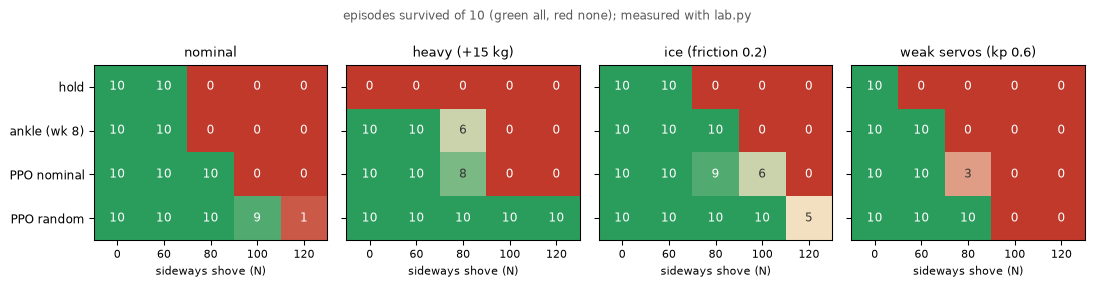

In [18]:
# Quoted from lab.py's docstring: measured with lab.py, 10 episodes per cell, sideways (~3.5 min).
pushes = (0, 60, 80, 100, 120)
names = ("hold", "ankle (wk 8)", "PPO nominal", "PPO random")
TABLE = {
    "nominal":              ((10, 10, 0, 0, 0), (10, 10, 0, 0, 0), (10, 10, 10, 0, 0), (10, 10, 10, 9, 1)),
    "heavy (+15 kg)":       ((0, 0, 0, 0, 0),   (10, 10, 6, 0, 0), (10, 10, 8, 0, 0),  (10, 10, 10, 10, 10)),
    "ice (friction 0.2)":   ((10, 10, 0, 0, 0), (10, 10, 10, 0, 0), (10, 10, 9, 6, 0), (10, 10, 10, 10, 5)),
    "weak servos (kp 0.6)": ((10, 0, 0, 0, 0),  (10, 10, 0, 0, 0), (10, 10, 3, 0, 0),  (10, 10, 10, 0, 0)),
}
from matplotlib.colors import LinearSegmentedColormap
cmap = LinearSegmentedColormap.from_list("survive", ["#c0392b", "#f4e1c1", "#2a9d5c"])
fig, axes = plt.subplots(1, 4, figsize=(11.5, 3.0), sharey=True)
for ax, (wname, rows) in zip(axes, TABLE.items()):
    M = np.array(rows)
    ax.imshow(M, cmap=cmap, vmin=0, vmax=10, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, M[i, j], ha="center", va="center", fontsize=9,
                    color="white" if M[i, j] <= 2 or M[i, j] >= 9 else "0.2")
    ax.set_xticks(range(len(pushes)), pushes, fontsize=8); ax.set_xlabel("sideways shove (N)", fontsize=8.5)
    ax.set_title(wname, fontsize=9.5)
axes[0].set_yticks(range(len(names)), names, fontsize=9)
fig.suptitle("episodes survived of 10 (green all, red none); measured with lab.py", fontsize=9, color="0.35")
fig.tight_layout(); plt.show()

Read a row: how big a shove that controller takes in that world. Read a
column of panels: which controller to ship to that world.

------------------------------------------------------------------------

## Reading the table (1): the nominal world

| controller | largest shove at 10 of 10 | above it |
|----|----|----|
| hold | 60 N | 0 of 10 at 80 N |
| ankle (week 8) | 60 N | 0 of 10 at 80 N |
| PPO nominal | 80 N | 0 of 10 at 100 N |
| PPO random | 80 N | **9 of 10 at 100 N**, 1 of 10 at 120 N |

- 3 M steps of PPO bought **20 N** over doing nothing, in the world it
  trained in.
- Week 8’s ankle rule buys nothing here. It turns the ankle pitches
  against the forward tilt $g_x$; the shove is sideways.
- The randomised policy is **not worse** in the nominal world; at 100 N
  it is better (9 against 0 is a real difference; 9 against 10 would not
  be).

------------------------------------------------------------------------

## Reading the table (2): worlds it did not train in

- **Heavy (+15 kg).** Holding the crouch falls with **no shove at all**.
  PPO nominal keeps 8 of 10 at 80 N, none at 100. PPO random takes **120
  N, 10 of 10** — 5 kg past the heaviest torso it ever trained on.
- **Ice (friction 0.2).** PPO nominal holds 80 N (9) and half of 100 N
  (6); PPO random holds 100 N (10) and half of 120 N (5).
- **Weak servos (kp 0.6).** Hold falls at 60 N. PPO nominal drops to 3
  of 10 at 80 N; PPO random keeps 80 N at 10 of 10 and falls at 100.
- **The ankle rule** helps where hold has no margin: 10 of 10 at 0 N
  heavy, where hold has none; 10 at 60 N on weak servos, where hold has
  none.

**PPO random is the best row in every world of this table**, including
three worlds just outside its training box. That is a margin, measured
here, for these three worlds — not a promise for the next one.

------------------------------------------------------------------------

## What randomisation cost, and what it bought

**Bought** (same 3 M decisions, same network, same reward):

| world | PPO nominal at 80 N | PPO random at 80 N | PPO random’s largest 10/10 |
|------------------|------------------|------------------|------------------|
| nominal | 10 | 10 | 80 N |
| heavy | 8 | 10 | 120 N |
| ice | 9 | 10 | 100 N |
| weak servos | 3 | 10 | 80 N |

**Cost.** None visible in this table: no cell where random is below
nominal. Randomisation has **no guaranteed price** — and no guaranteed
gift. A wider box makes the task harder and can teach a timid policy; on
another task it can cost accuracy in the nominal world. A cost shows up
as a lower count in the nominal row, so that row is always measured.

**Each policy is one training seed.** A claim about randomisation in
general needs more than one run on each side.

------------------------------------------------------------------------

## The sim-to-real gap: a world you did not randomise

A real G1 differs from ours in more than three numbers. Each is a world
outside every training box until someone adds it:

| gap | what it does | how it is usually handled |
|------------------------|------------------------|------------------------|
| **latency** | the action arrives a step or more late | delay the action in simulation |
| **sensor noise, bias** | the IMU drifts (week 6) | add noise and bias to observations |
| **motor model** | torque limits, saturation, heating | randomise, or learn an actuator model |
| **contact** | feet, soles, floors | randomise friction, restitution, terrain |
| **the body** | masses, lengths, joint offsets | randomise, or measure (system identification) |

Too narrow a range leaves the gap uncovered; too wide makes the task
harder. **Choosing the ranges is the engineering**; the lab’s table,
with the new world as a row, is the test.

------------------------------------------------------------------------

## A non-result, stated honestly

A **privileged teacher** observes what no real robot can measure, to be
distilled into a deployable student later (week 10).
`G1PushEnv(privileged=True)` appends nine such numbers: pelvis velocity
(3) and height (1), the shove being applied now (2), and this episode’s
friction, mass and stiffness (3).

Trained with the **same 3 M-step budget**, it was **worse** in the
nominal world than either shipped policy: **3 of 10 at 60 N** (measured
when this week was built; the checkpoint is not shipped).

- More information did not buy more robustness here: a larger
  observation is a harder search at a fixed budget.
- **Do not claim privileged information helps on this task.** Making a
  teacher that does is open.

------------------------------------------------------------------------

## Lab class on your laptop

``` bash
uv sync --extra rl                                          # once
uv run weeks/09-scale-and-robustness/lab.py                 # the table (~3.5 min), then a replay
uv run weeks/09-scale-and-robustness/lab.py --episodes 3    # quicker, noisier
uv run weeks/09-scale-and-robustness/lab.py --any-direction # shoves from every side
```

**You change** `WORLDS` (section 1 of `lab.py`: friction, mass, kp per
world) and `PUSHES`. **You see** the table, row by row, then `--replay`
(default `"PPO random"`) in the first world with a 100 N shove in the
viewer. As shipped it prints the table on the *Lab’s table* slide.

**Try** (write the prediction first):

1.  A world **outside** the training range, e.g. `mass=+25` or
    `friction=0.1`. Does PPO random still win there?
2.  `kp=0.5`: which policy degrades most gracefully?
3.  `--any-direction`: which policy was trained for that? Which side is
    hardest?
4.  Which row would you send to a real robot whose mass you know only to
    ±5 kg?

------------------------------------------------------------------------

## For your term project

The term project (weeks 12–15):
[`weeks/projects/README.md`](https://github.com/gnoejh/soc4180/blob/main/weeks/projects/README.md);
the list:
[`catalogue.md`](https://github.com/gnoejh/soc4180/blob/main/weeks/projects/catalogue.md).

- **P8 — learned push recovery: randomisation that helps.** The direct
  continuation. Use the shipped checkpoints as the twin; retraining is 3
  M decisions, ~16 min on 36 cores and hours on a laptop — **plan the
  compute** with this week’s arithmetic (measure your own
  ${\color{#2a9d5c}{r}}$ first).
- **P2 — the walker on hard ground**: the same table for week 4’s
  open-loop walker (no learning, no compute bill).
- **P7 — a planner with a wrong model**: robustness of MPPI (week 10) to
  a model that is wrong, instead of a world.
- **P14 — your own**: any question that follows the method.

**The method.** A **prediction** with a number, before the first run; a
**twin** that changes one thing; every number from **`results.csv`**; a
**`CHECK`** line decided before the final run; **exact-size shoves** and
counts of 10; **never grade convergence** — grade the diagnosis.

------------------------------------------------------------------------

## Next week

**Week 10 — planning and imitation.** Everything since week 7 learns
*before* the robot moves. Next week the robot searches *while* it moves:
at every decision it runs MuJoCo forward many times from the present and
picks the best future — model-predictive control by sampling. Then an
expensive expert teaches a cheap student, and we find when that works.